# データサイエンス実践A 第12講：遊び心のあるグラフ・伝わるグラフ
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月17日（火）**

1. 最初に**第２回課題の解説**を聞き、自分のコードと見比べる。
1. **画像や記号をマーカー**にして、記憶に残るグラフを作る。
1. 遊ぶのは「伝わる」が守られている範囲で。**誤解を招くグラフ**の例を、正しい描き方と並べて見る。
1. **第３回課題**に向けたチェックリストを確かめる。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[第２回課題の解説](#第２回課題の解説)**

**[AH. 遊び心のあるグラフ](#AH.-遊び心のあるグラフ)**
- [AH-0 今日の完成形](#AH-0-今日の完成形)
- [AH-1 画像をマーカーにする](#AH-1-画像をマーカーにする)
- [AH-2 記号をマーカーにする](#AH-2-記号をマーカーにする)
- [AH-3 背景に画像を敷く](#AH-3-背景に画像を敷く)

**[AI. 伝わるグラフ・誤解を招くグラフ](#AI.-伝わるグラフ・誤解を招くグラフ)**
- [AI-1 縦軸を途中から始めた棒グラフ](#AI-1-縦軸を途中から始めた棒グラフ)
- [AI-2 項目が多すぎる円グラフ](#AI-2-項目が多すぎる円グラフ)
- [AI-3 第３回課題に向けたチェックリスト](#AI-3-第３回課題に向けたチェックリスト)

**[AJ. 発展（できる人だけ）](#AJ.-発展（できる人だけ）)**
- [AJ-1 手書き風のグラフ](#AJ-1-手書き風のグラフ)
- [AJ-2 手書き風フォントを入れると（紹介）](#AJ-2-手書き風フォントを入れると（紹介）)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は7種類のグラフの総復習をした
- 第２回課題（締切 11/16）を提出した
- グラフは「何を見せたいか」で選ぶ。どれも **Excel を読む → 列を取り出す → 描く** の3段
- 今日使う画像 `sweets_montblanc.png` を、notebook と同じいつもの場所（ホームフォルダ）に置いておく

---
# 第２回課題の解説

- 解説は授業HPの解答例を見ながら行う
- 自分のコードと見比べて、**違うところ**と**エラーになったところ**をメモする
- 直したコードは下のセルに貼って、もう一度実行してみる

In [ ]:
# 第２回課題のコードを貼り付けて、直してみよう

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

- 2行目の `from matplotlib.offsetbox import …` は、画像をマーカーにするための道具（AH-1 で使う）

---
# AH. 遊び心のあるグラフ

## AH-0 今日の完成形

月ごとのモンブランの売上を、**モンブランの画像**をマーカーにして描いたもの。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**数や大きさを変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[3]）の働きを1つずつ学ぶ（AH-1〜AH-3）

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

img = plt.imread('sweets_montblanc.png')  # [1] 画像を読む
y = [30, 52, 61, 45, 20]

plt.figure(figsize=(8, 5))
plt.plot([0, 1, 2, 3, 4], y, color='saddlebrown', zorder=1)
for i in range(len(y)):  # [2] 画像のマーカー
    box = AnnotationBbox(OffsetImage(img, zoom=0.08), (i, y[i]), frameon=False)
    plt.gca().add_artist(box)
plt.imshow(img, extent=[-0.5, 4.5, 0, 80], alpha=0.1, aspect='auto')  # [3] 背景
plt.xticks([0, 1, 2, 3, 4], ['9月', '10月', '11月', '12月', '1月'])
plt.xlim(-0.5, 4.5)
plt.ylim(0, 80)
plt.title('モンブランの売上（個）', fontsize=16)
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `zoom=0.08` → `zoom=0.15`（画像の大きさ）
- `alpha=0.1` → `alpha=0.4`（背景の濃さ）
- `y` の数を変える（例：`[30, 52, 61, 45, 20]` → `[10, 20, 70, 60, 30]`）

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 画像を読む | `img = plt.imread('画像ファイル名')` | AH-1 |
| [2] | 画像のマーカー | `for` で1つずつ `AnnotationBbox(OffsetImage(img, zoom=…), (x, y))` | AH-1 |
| [3] | 背景の画像 | `plt.imshow(img, extent=[…], alpha=0.1, aspect='auto')` | AH-3 |

In [ ]:
# 上のコードを貼り付けて、値を変えてみよう

## AH-1 画像をマーカーにする

- 下のセルは**ひな形**。写して使えばよく、1行ずつ覚えなくてよい
- 変えるのは `画像ファイル名`・`x`・`y`・`zoom`（画像の大きさ）だけ
- 画像は、背景が透明な png（「いらすとや」の画像など）を使うときれいに見える

In [ ]:
img = plt.imread('sweets_montblanc.png')
x = [1, 2, 3, 4, 5]
y = [3, 5, 2, 6, 4]

plt.figure(figsize=(6, 4))
plt.plot(x, y, color='saddlebrown', zorder=1)
for i in range(len(x)):
    box = AnnotationBbox(OffsetImage(img, zoom=0.08), (x[i], y[i]), frameon=False)
    plt.gca().add_artist(box)
plt.xlim(0, 6)
plt.ylim(0, 7)
plt.title('月ごとのモンブランの売上')
plt.xlabel('月')
plt.ylabel('個数')
plt.show()

- `for i in range(len(x)):` で、点の数だけ画像を置いている（第８講の for と range）
- `(x[i], y[i])` は i 番目の点の位置
- 画像は `plt.xlim`・`plt.ylim` の範囲を自動で広げない。範囲は自分で指定する

## AH-2 記号をマーカーにする

- 第３講のハートのように、`$` で囲んだ記号をマーカーにできる
- `'$\\star$'`（星）、`'$\\clubsuit$'`（クラブ）、`'$\\bigodot$'`（二重丸）など。文字そのもの `'$A$'` も使える

In [ ]:
x = [1, 2, 3, 4, 5]
plt.scatter(x, [2, 3, 2, 4, 3], marker='$\\heartsuit$', s=400, color='hotpink', label='ハート')
plt.scatter(x, [5, 6, 5, 7, 6], marker='$\\star$', s=400, color='gold', label='星')
plt.scatter(x, [8, 9, 8, 10, 9], marker='$A$', s=300, color='teal', label='文字A')
plt.ylim(0, 15)
plt.legend(loc='upper center', ncol=3)
plt.show()

- `\\` は `\` を書くための書き方（Python の文字列の中では `\` を2つ重ねる）
- `s=` はマーカーの大きさ（散布図では `s`、折れ線では `markersize`）

## AH-3 背景に画像を敷く

- `plt.imshow(画像, extent=[x最小, x最大, y最小, y最大])` で、グラフの範囲いっぱいに画像を敷ける
- `alpha=` で薄くする。`aspect='auto'` を付けないと、画像の縦横の比に合わせてグラフがつぶれる

In [ ]:
x = [1, 2, 3, 4, 5]
y = [3, 5, 2, 6, 4]
plt.imshow(img, extent=[0, 6, 0, 7], alpha=0.25, aspect='auto')
plt.plot(x, y, marker='o', color='saddlebrown', linewidth=3)
plt.xlim(0, 6)
plt.ylim(0, 7)
plt.show()

### 使ってみよう
- 好きな画像（png）を同じフォルダに置き、AH-1 のひな形の `'sweets_montblanc.png'` を書き換えてみよう
- データは自分で考えた数でよい（例：1週間に飲んだコーヒーの杯数）

In [ ]:
# ここで試してみよう

---
# AI. 伝わるグラフ・誤解を招くグラフ

遊ぶのは「伝わる」が守られている範囲で。よくある失敗を、正しい描き方と並べて見る。

## AI-1 縦軸を途中から始めた棒グラフ

- 左は 90 から始めているので、A と B の差が何倍にも見える。**棒グラフの縦軸は 0 から**

In [ ]:
names = ['A', 'B', 'C']
values = [95, 97, 99]

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.bar(names, values, color='tomato')
plt.ylim(90, 100)
plt.title('誤解を招く（90から）')

plt.subplot(1, 2, 2)
plt.bar(names, values, color='steelblue')
plt.ylim(0, 100)
plt.title('正しい（0から）')
plt.tight_layout()
plt.show()

- 棒グラフは「棒の長さ」で大きさを比べる。途中から始めると、長さの比が実際の値の比と合わなくなる
- 折れ線グラフは「変化」を見るので、途中から始めてもよい（ただし軸の数字ははっきり書く）

## AI-2 項目が多すぎる円グラフ

- 項目が多いと、小さい扇形が読めなくなる。**5つくらいまで**にして、残りは「その他」にまとめる

In [ ]:
names = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
values = [30, 20, 15, 10, 8, 6, 4, 3, 2, 2]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.pie(values, labels=names, startangle=90, counterclock=False)
plt.title('項目が多すぎる')

plt.subplot(1, 2, 2)
plt.pie(values[:4] + [sum(values[4:])], labels=names[:4] + ['その他'],
        autopct='%1.0f%%', startangle=90, counterclock=False)
plt.title('上位4つ＋その他')
plt.show()

- `values[:4]` は前から4つ、`values[4:]` は5つ目から最後まで（リストの切り出し）。`sum()` で合計する

## AI-3 第３回課題に向けたチェックリスト

| よくある失敗 | どうする |
|---|---|
| 棒グラフの縦軸が 0 から始まっていない | `plt.ylim(0, …)` |
| 立体（3D）の円グラフ | 手前が大きく見える。平らな円グラフか棒グラフにする |
| 項目が多すぎる円グラフ | 5つくらいまで。残りは「その他」にまとめる |
| 軸の名前・単位がない | `plt.xlabel`・`plt.ylabel` に単位まで書く（例：`'降水量 (mm)'`） |
| 色が多すぎる・赤と緑で区別している | 色は意味のあるところだけ。赤と緑は見分けにくい人がいるので、青とオレンジなどにする |
| 凡例がなく、どの線が何か分からない | `label=` ＋ `plt.legend()` |
| 文字が小さくて読めない | `fontsize=14` など。スライドに貼るなら大きめに |
| データの出どころが書いていない | 図の下や説明文に「出典：e-Stat ○○統計」などと書く |
| 画像やイラストでデータが読みにくい | 遊び心は**データが読める範囲で** |

> **第３回課題に向けて**：自分のグラフで、この表を1つずつ確かめる

---
# AJ. 発展（できる人だけ）

## AJ-1 手書き風のグラフ

- `with plt.xkcd():` の下に字下げして書くと、手書き風になる
- **2行目のフォントの指定は必ず写す**。手書き風にすると文字が英語用のフォントに切り替わり、日本語が □ になるため
  - `'Comic Sans MS'`（英数字を手書き風に）→ 無い文字は `'IPAexGothic'`（japanize_matplotlib に入っている日本語フォント）で表示される
- 字下げした部分だけが手書き風になる。次のセルからは元に戻る

In [ ]:
with plt.xkcd():
    plt.rcParams['font.family'] = ['Comic Sans MS', 'IPAexGothic']
    plt.plot([1, 2, 3, 4, 5], [1, 2, 4, 8, 16], marker='o')
    plt.title('やる気の伸び（予想）')
    plt.xlabel('授業の回')
    plt.ylabel('やる気')
    plt.show()

- Mac で `Comic Sans MS` が無いときは、英数字も `IPAexGothic` で表示される（エラーにはならない）

## AJ-2 手書き風フォントを入れると（紹介）

- パソコンに手書き風のフォントを入れると、文字ももっと手書きらしくできる
- 下の図は、無料で配布されているフォントを入れたパソコンで描いたもの（左上が AJ-1 の組み合わせ）

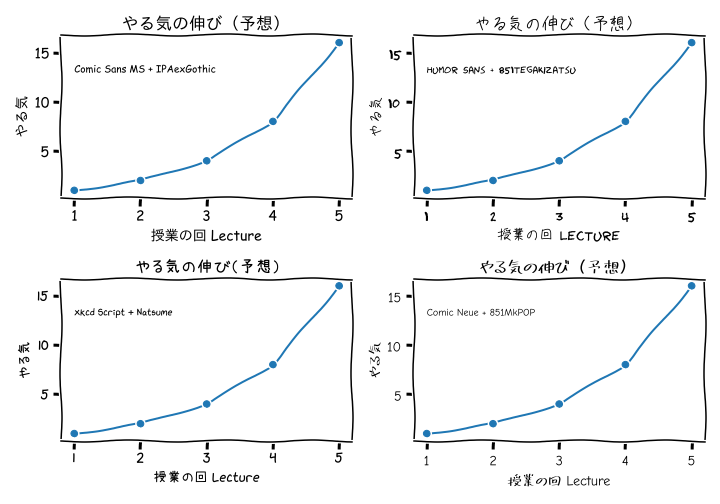

| 種類 | フォント | `font.family` に書く名前 |
|---|---|---|
| 英数字 | Humor Sans（xkcd の漫画の文字） | `'Humor Sans'` |
| 英数字 | xkcd Script | `'xkcd Script'` |
| 英数字 | Comic Neue | `'Comic Neue'` |
| 日本語 | 851手書き雑フォント | `'851tegakizatsu'` |
| 日本語 | なつめもじ | `'Natsume'` |
| 日本語 | 851マカポップ | `'851MkPOP'` |

### フォントの入れ方（例：851マカポップ）

1. [851MkPOP_101.ttf](https://pm85122.onamae.jp/851MkPOP_101.ttf) をダウンロードする（約 4.5MB）。ほかのフォントは、フォント名で検索すると配布ページが見つかる
1. ダウンロードしたファイルを開いて「インストール」（Windows は右クリック →「インストール」、Mac はダブルクリック →「Font Book」で「インストール」）
1. matplotlib が覚えているフォントの一覧（キャッシュ）を消す。下のセルで出てくるフォルダ（Windows は `C:\Users\自分の名前\.matplotlib`、Mac はホームフォルダの `.matplotlib`）を開き、`fontlist-` で始まる `.json` ファイル（例：`fontlist-v3.11.0.json`）を**全部**消す
   - `.` で始まるフォルダは隠しフォルダ。Windows はエクスプローラーの「表示」→「隠しファイル」にチェック、Mac は Finder で `Command` + `Shift` + `.`（ピリオド）
1. Kernel → Restart して、もう一度 `import` から実行する

```python
import matplotlib
print(matplotlib.get_cachedir())
```

- 書く名前はファイル名と違うことがある。入れたフォントの名前は、下のセルで一覧を出して探す


In [ ]:
from matplotlib import font_manager
names = sorted({f.name for f in font_manager.fontManager.ttflist})
print(names)

In [ ]:
fonts = [
    ['Comic Sans MS', 'IPAexGothic'],
    ['Humor Sans', '851tegakizatsu', 'IPAexGothic'],
    ['xkcd Script', 'Natsume', 'IPAexGothic'],
    ['Comic Neue', '851MkPOP', 'IPAexGothic'],
]

with plt.xkcd():
    plt.figure(figsize=(10, 7))
    for i in range(len(fonts)):
        plt.rcParams['font.family'] = fonts[i]
        plt.subplot(2, 2, i + 1)
        plt.plot([1, 2, 3, 4, 5], [1, 2, 4, 8, 16], marker='o')
        plt.title('やる気の伸び（予想）')
        plt.xlabel('授業の回 Lecture')
        plt.ylabel('やる気')
        plt.text(1, 13, fonts[i][0] + ' + ' + fonts[i][1], fontsize=10)
    plt.tight_layout()
    plt.show()

- 最後の `'IPAexGothic'` は、フォントが入っていないときの予備。入っていない人が実行しても日本語は □ にならない
- フォントを入れたのに変わらないとき、`findfont: Font family '851MkPOP' not found.` と出るときは、キャッシュを消していないか、消した後に Kernel → Restart していない（上の「フォントの入れ方」の 3・4）

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| 画像を読む | `img = plt.imread('画像ファイル名')` |
| 画像をマーカーに | AH-1 のひな形を写し、`x`・`y`・`zoom` を変える |
| 記号をマーカーに | `marker='$\\star$'`、`marker='$A$'` |
| 背景に画像 | `plt.imshow(img, extent=[x最小, x最大, y最小, y最大], alpha=0.25, aspect='auto')` |

- 棒グラフの縦軸は **0 から**。円グラフの項目は **5つくらいまで**
- 第３回課題では、AI-3 のチェックリストで自分のグラフを確かめる

次回（第13講）は**関数と内包表記を読む**、**実データを整えて読む**。